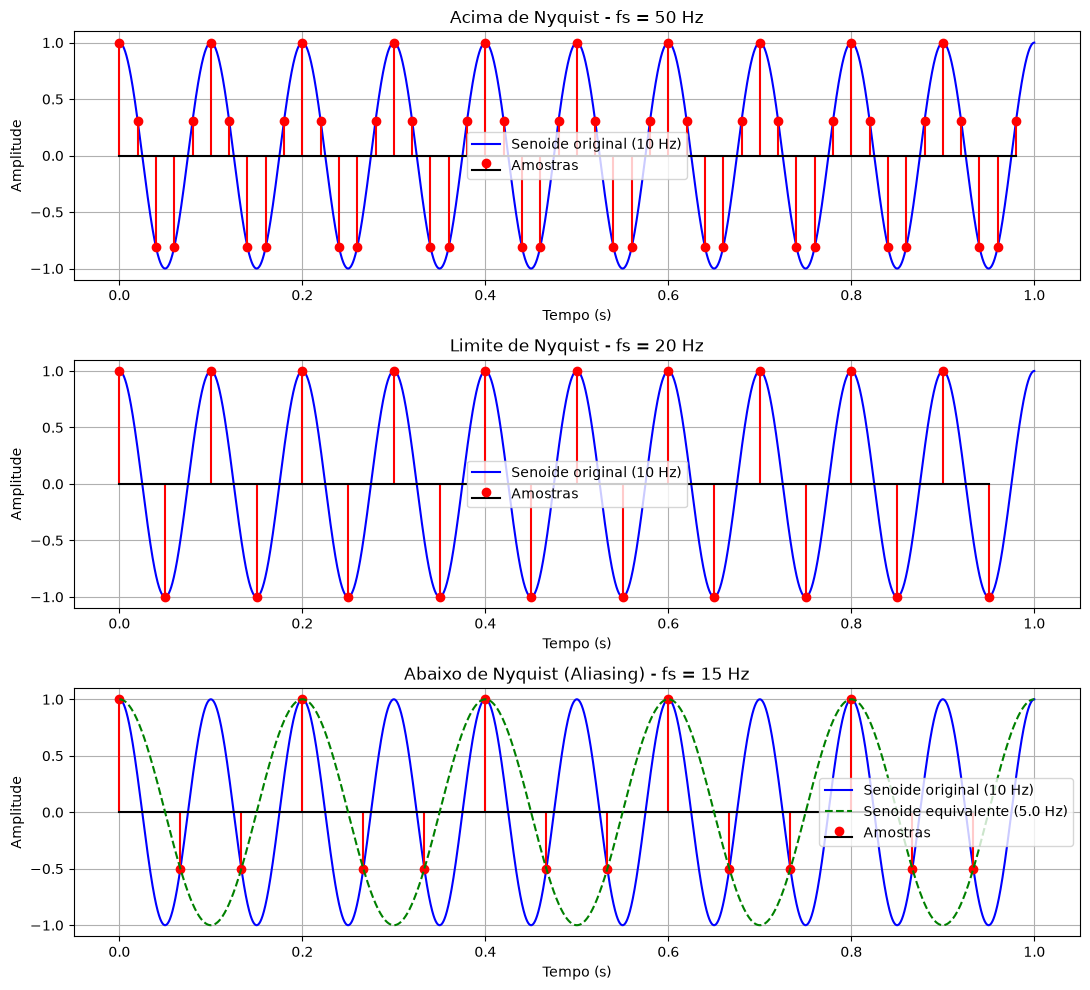

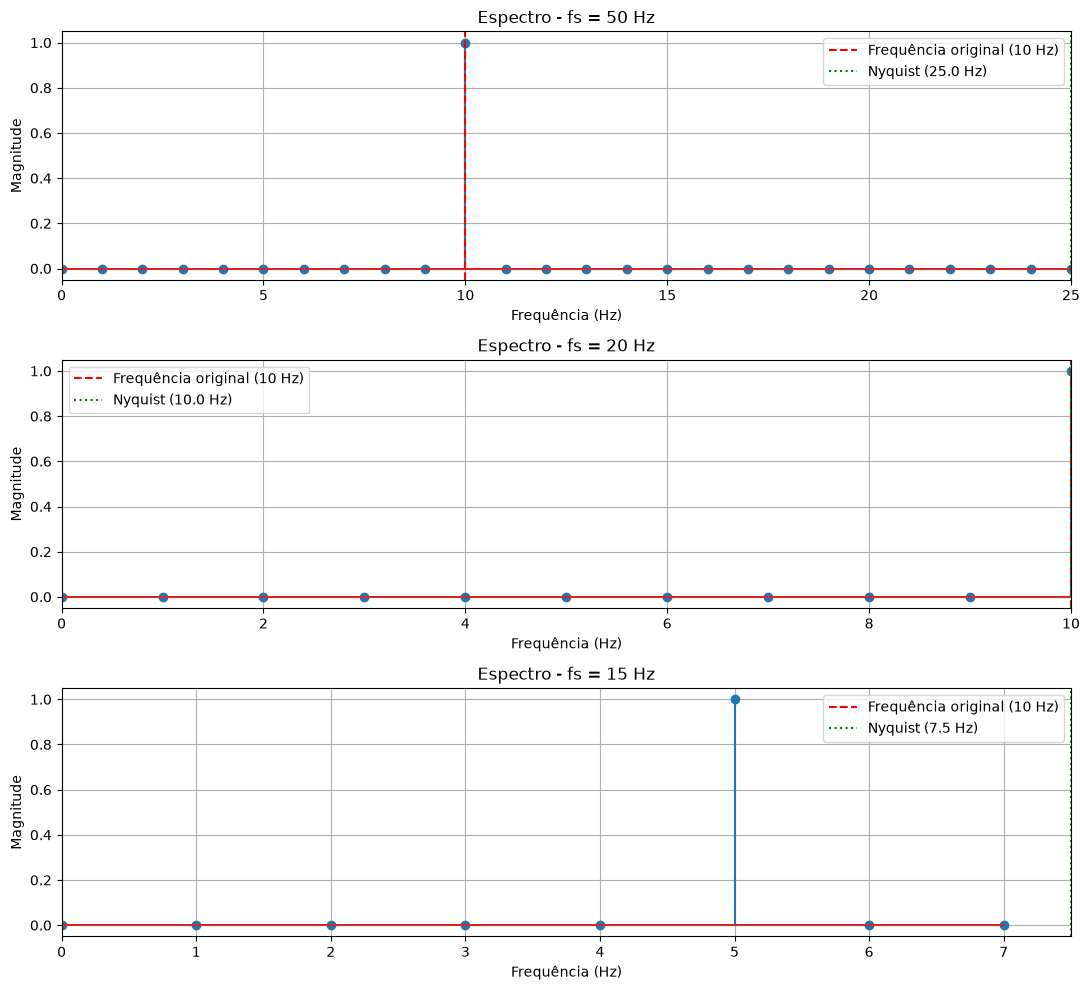

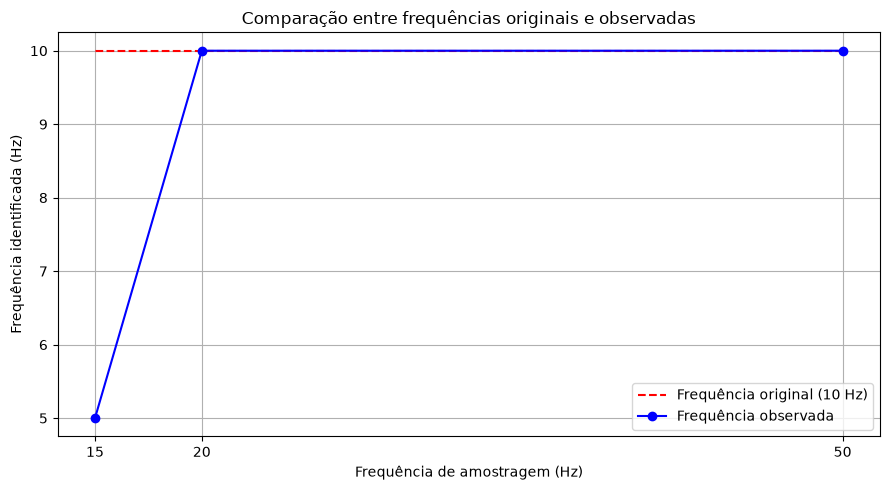

ANÁLISE DO TEOREMA DE NYQUIST
Frequência original: 10 Hz
Frequência mínima de Nyquist: 20 Hz

-------------------------------------------
Condição: Acima de Nyquist
Frequência de amostragem: 50 Hz
Frequência de Nyquist: 25.0 Hz
Número de amostras: 50
Frequência identificada no espectro: 10.00 Hz
Primeiras 10 amostras:
[ 1.     0.309 -0.809 -0.809  0.309  1.     0.309 -0.809 -0.809  0.309]

-------------------------------------------
Condição: Limite de Nyquist
Frequência de amostragem: 20 Hz
Frequência de Nyquist: 10.0 Hz
Número de amostras: 20
Frequência identificada no espectro: 10.00 Hz
Primeiras 10 amostras:
[ 1. -1.  1. -1.  1. -1.  1. -1.  1. -1.]

-------------------------------------------
Condição: Abaixo de Nyquist (Aliasing)
Frequência de amostragem: 15 Hz
Frequência de Nyquist: 7.5 Hz
Número de amostras: 15
Frequência identificada no espectro: 5.00 Hz
Primeiras 10 amostras:
[ 1.  -0.5 -0.5  1.  -0.5 -0.5  1.  -0.5 -0.5  1. ]

Simulação concluída!


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURAÇÕES GERAIS
# ============================================================

f0 = 10                  # Frequência da senoide original (Hz)
A = 1.0                  # Amplitude
phi = 0                  # Fase inicial (rad)

# Frequências de amostragem para os três experimentos
frequencias_amostragem = [50, 20, 15]

# Frequência de Nyquist da senoide original
f_nyquist_original = 2 * f0

# Duração da simulação
T = 1.0

# Tempo contínuo simulado (alta resolução)
fs_continuo = 10000

t_continuo = np.arange(
    0, T, 1/fs_continuo
)

# Senoide contínua simulada
x_continuo = A * np.cos(
    2 * np.pi * f0 * t_continuo + phi
)


# ============================================================
# 2. FUNÇÃO PARA CALCULAR O ESPECTRO
# ============================================================

def calcular_espectro(x, fs):

    N = len(x)

    # FFT de apenas um lado do espectro
    X = np.fft.rfft(x)

    # Eixo de frequências
    frequencias = np.fft.rfftfreq(N, d=1/fs)

    # Magnitude normalizada
    magnitude = np.abs(X) / N

    # Correção para espectro unilateral
    if N % 2 == 0:
        magnitude[1:-1] *= 2
    else:
        magnitude[1:] *= 2

    return frequencias, magnitude


# ============================================================
# 3. FUNÇÃO PARA IDENTIFICAR A FREQUÊNCIA OBSERVADA
# ============================================================

def identificar_frequencia(frequencias, magnitude):

    # Ignora a componente DC
    indice = np.argmax(magnitude[1:]) + 1

    return frequencias[indice]


# ============================================================
# 4. SIMULAÇÃO DOS TRÊS CASOS
# ============================================================

resultados = []

for fs in frequencias_amostragem:

    # Frequência de Nyquist
    f_nyquist = fs / 2

    # Geração das amostras
    n = np.arange(int(fs * T))
    t_amostras = n / fs

    x_amostras = A * np.cos(
        2 * np.pi * f0 * t_amostras + phi
    )

    # Cálculo do espectro
    frequencias, magnitude = calcular_espectro(
        x_amostras, fs
    )

    # Identificação da frequência observada
    f_observada = identificar_frequencia(
        frequencias, magnitude
    )

    # Classificação da condição
    if fs > 2 * f0:
        condicao = "Acima de Nyquist"

    elif fs == 2 * f0:
        condicao = "Limite de Nyquist"

    else:
        condicao = "Abaixo de Nyquist (Aliasing)"

    resultados.append({
        "fs": fs,
        "n": n,
        "tempo": t_amostras,
        "amostras": x_amostras,
        "frequencias": frequencias,
        "magnitude": magnitude,
        "nyquist": f_nyquist,
        "observada": f_observada,
        "condicao": condicao
    })


# ============================================================
# 5. GRÁFICOS NO DOMÍNIO DO TEMPO
# ============================================================

fig, axes = plt.subplots(
    3, 1, figsize=(11, 10)
)

for ax, resultado in zip(axes, resultados):

    fs = resultado["fs"]

    # Senoide contínua simulada
    ax.plot(
        t_continuo,
        x_continuo,
        label="Senoide original (10 Hz)",
        color="blue"
    )

    # Amostras obtidas
    ax.stem(
        resultado["tempo"],
        resultado["amostras"],
        linefmt="red",
        markerfmt="ro",
        basefmt="k-",
        label="Amostras"
    )

    # Frequência equivalente observada
    if fs < 2 * f0:

        x_alias = A * np.cos(
            2 * np.pi * resultado["observada"] * t_continuo
        )

        ax.plot(
            t_continuo,
            x_alias,
            "--",
            color="green",
            label=f"Senoide equivalente ({resultado['observada']:.1f} Hz)"
        )

    ax.set_title(
        f"{resultado['condicao']} - fs = {fs} Hz"
    )

    ax.set_xlabel("Tempo (s)")
    ax.set_ylabel("Amplitude")

    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 6. ESPECTROS DE MAGNITUDE
# ============================================================

fig, axes = plt.subplots(
    3, 1, figsize=(11, 10)
)

for ax, resultado in zip(axes, resultados):

    ax.stem(
        resultado["frequencias"],
        resultado["magnitude"]
    )

    ax.axvline(
        f0,
        color="red",
        linestyle="--",
        label=f"Frequência original ({f0} Hz)"
    )

    ax.axvline(
        resultado["nyquist"],
        color="green",
        linestyle=":",
        label=f"Nyquist ({resultado['nyquist']} Hz)"
    )

    ax.set_xlim(0, resultado["fs"] / 2)

    ax.set_title(
        f"Espectro - fs = {resultado['fs']} Hz"
    )

    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Magnitude")

    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 7. COMPARAÇÃO DAS FREQUÊNCIAS OBSERVADAS
# ============================================================

frequencias_observadas = [
    r["observada"] for r in resultados
]

plt.figure(figsize=(9, 5))

plt.plot(
    frequencias_amostragem,
    [f0] * len(frequencias_amostragem),
    "r--",
    label="Frequência original (10 Hz)"
)

plt.plot(
    frequencias_amostragem,
    frequencias_observadas,
    "bo-",
    label="Frequência observada"
)

plt.xlabel("Frequência de amostragem (Hz)")
plt.ylabel("Frequência identificada (Hz)")

plt.title("Comparação entre frequências originais e observadas")

plt.xticks(frequencias_amostragem)

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 8. RELATÓRIO DOS RESULTADOS
# ============================================================

print("ANÁLISE DO TEOREMA DE NYQUIST")
print("=" * 65)

print(f"Frequência original: {f0} Hz")
print(f"Frequência mínima de Nyquist: {2*f0} Hz")

for resultado in resultados:

    print("\n-------------------------------------------")

    print(f"Condição: {resultado['condicao']}")
    print(f"Frequência de amostragem: {resultado['fs']} Hz")
    print(f"Frequência de Nyquist: {resultado['nyquist']} Hz")
    print(f"Número de amostras: {len(resultado['n'])}")
    print(
        f"Frequência identificada no espectro: "
        f"{resultado['observada']:.2f} Hz"
    )

    print("Primeiras 10 amostras:")

    print(
        np.round(
            resultado["amostras"][:10],
            4
        )
    )

print("\nSimulação concluída!")
